# 3. Transaction costs: when to trade

Part 1 ended on a trade-off. Rebalancing more often reduces the hedging error, like $1/\sqrt{N}$, but every rebalancing is a trade. Without frictions trades are free and the delta hedge is optimal. Here each trade costs a fraction $\varepsilon$ of its value, and the question becomes when it is worth trading at all.

**Setting.** Same market and option as in part 1 ($\sigma = 35\%$, $T = 3$ months, $N = 30$, $K = 1$). Proportional costs $\varepsilon\,|H_j - H_{j-1}|\,S_{t_j}$ are paid on every trade, including the initial purchase and the final liquidation at $T$. The seller's loss is

$$
X = (S_T - K)^+ - \sum_{j=0}^{N-1} H_j\,(S_{t_{j+1}} - S_{t_j}) + \varepsilon \sum_{j=0}^{N} |H_j - H_{j-1}|\, S_{t_j}, \qquad H_{-1} = H_N = 0,
$$

and, as in part 2, the price she charges is $\mathrm{AVaR}_{0.9}(X)$. Lower is better.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import blackscholes as bs, simulate
from deephedge.benchmarks import band_holdings, delta_holdings, tune_band
from deephedge.losses import avar, avar_objective, hedging_loss, turnover
from deephedge.models import PositionHedge
from deephedge.plotting import COLORS, MUTED, style, save
from deephedge.train import fit

N, T, sigma = 30, 0.25, 0.35
S_train = simulate.gbm_paths(100_000, seed=0).float()
S_test = simulate.gbm_paths(100_000, seed=1)

## How much do costs hurt the delta hedge?

In [2]:
p = bs.price(1.0, 1.0, T, sigma).item()
H_delta = delta_holdings(S_test, sigma)

print(f"Black-Scholes price of the call: {p:.5f}\n")
print(f"{'cost':>7s}{'mean cost paid':>16s}{'cost / premium':>16s}{'AVaR_0.9 of X':>16s}")
for eps in [0.0, 0.001, 0.005, 0.01]:
    X, costs = hedging_loss(H_delta, S_test, eps=eps)
    print(f"{eps:7.1%}{costs.mean():16.5f}{costs.mean() / p:16.1%}{avar(X, 0.9):16.5f}")

print(f"\nDelta hedge with 0.5% costs, as the number of rebalancing dates grows")
print(f"{'N':>5s}{'std of X without costs':>24s}{'mean cost paid':>16s}{'AVaR_0.9 of X':>16s}")
for n in [5, 10, 30, 90, 270]:
    S_n = simulate.gbm_paths(100_000, seed=100 + n, n_steps=n)
    H_n = delta_holdings(S_n, sigma)
    X0, _ = hedging_loss(H_n, S_n)
    X, costs = hedging_loss(H_n, S_n, eps=0.005)
    print(f"{n:5d}{X0.std():24.5f}{costs.mean():16.5f}{avar(X, 0.9):16.5f}")

Black-Scholes price of the call: 0.06973

   cost  mean cost paid  cost / premium   AVaR_0.9 of X
   0.0%         0.00000            0.0%         0.08998
   0.1%         0.00277            4.0%         0.09340
   0.5%         0.01385           19.9%         0.10766
   1.0%         0.02770           39.7%         0.12632

Delta hedge with 0.5% costs, as the number of rebalancing dates grows
    N  std of X without costs  mean cost paid   AVaR_0.9 of X
    5                 0.02568         0.00835         0.12951
   10                 0.01853         0.01003         0.11722


   30                 0.01092         0.01389         0.10788


   90                 0.00640         0.02031         0.10883


  270                 0.00371         0.03131         0.12129


Costs eat the premium quickly: at 1% per trade the delta hedge pays 40% of the option's value in costs, and the price the seller must charge rises by 40%, from 0.090 to 0.126. The second table puts a price on the dilemma of part 1: rebalancing more often keeps reducing the hedging error, but beyond about 30 dates the extra costs outweigh it and the AVaR goes back up. The delta hedge has no way to decide which trades are worth making.

## A network that knows its position

Without costs the best holding depends only on the current state. With costs it also depends on the position already held: if it is close to the target, adjusting it costs more than it protects. Each network $j$ therefore receives the current price **and** the inherited holding $H_{j-1}$, and outputs the trade, $H_j = H_{j-1} + f_j(S_{t_j}, H_{j-1})$. Doing nothing is an output of zero.

One model per cost level, trained on the AVaR objective of part 2 with the costs inside the loss. Same optimiser as before, 30 epochs.

In [3]:
eps_levels = [0.0, 0.002, 0.005, 0.01]


def train(eps, seed=0):
    torch.manual_seed(seed)
    model = PositionHedge(S_train)
    objective = lambda m, s: avar_objective(hedging_loss(m(s), s, eps=eps)[0], m.w, 0.9)
    return fit(model, (S_train,), objective, progress=False)[0]


def holdings(model, S):
    with torch.no_grad():
        return model(S.float()).double()


models = {eps: train(eps) for eps in eps_levels}

print(f"{'cost':>7s}{'delta':>10s}{'deep':>10s}{'change':>9s}{'cost paid, delta':>18s}{'deep':>8s}{'shares traded, delta':>22s}{'deep':>8s}")
for eps in eps_levels:
    H_deep = holdings(models[eps], S_test)
    X_d, c_d = hedging_loss(H_delta, S_test, eps=eps)
    X_n, c_n = hedging_loss(H_deep, S_test, eps=eps)
    print(f"{eps:7.1%}{avar(X_d, 0.9):10.5f}{avar(X_n, 0.9):10.5f}{avar(X_n, 0.9) / avar(X_d, 0.9) - 1:9.1%}"
          f"{c_d.mean():18.5f}{c_n.mean():8.5f}{turnover(H_delta).mean():22.3f}{turnover(H_deep).mean():8.3f}")

   cost     delta      deep   change  cost paid, delta    deep  shares traded, delta    deep


   0.0%   0.08998   0.08883    -1.3%           0.00000 0.00000                 2.707   2.616


   0.2%   0.09688   0.09436    -2.6%           0.00554 0.00503                 2.707   2.457


   0.5%   0.10766   0.10213    -5.1%           0.01385 0.01178                 2.707   2.299


   1.0%   0.12632   0.11415    -9.6%           0.02770 0.02176                 2.707   2.123


Without costs the network is slightly better than delta (−1.3%): in discrete time the delta hedge is not exactly optimal for the AVaR. As costs grow the network trades less, 2.1 shares over the life of the option against 2.7 for delta at 1%, and its gain over delta reaches 9.6%.

## How does the network trade less?

                          mean |trade|  trades < 0.01 share  mean |H - delta|
delta hedge                     0.0589                20.5%            0.0000
deep hedge, no costs            0.0553                17.5%            0.0215
deep hedge, 1% costs            0.0388                24.5%            0.0509


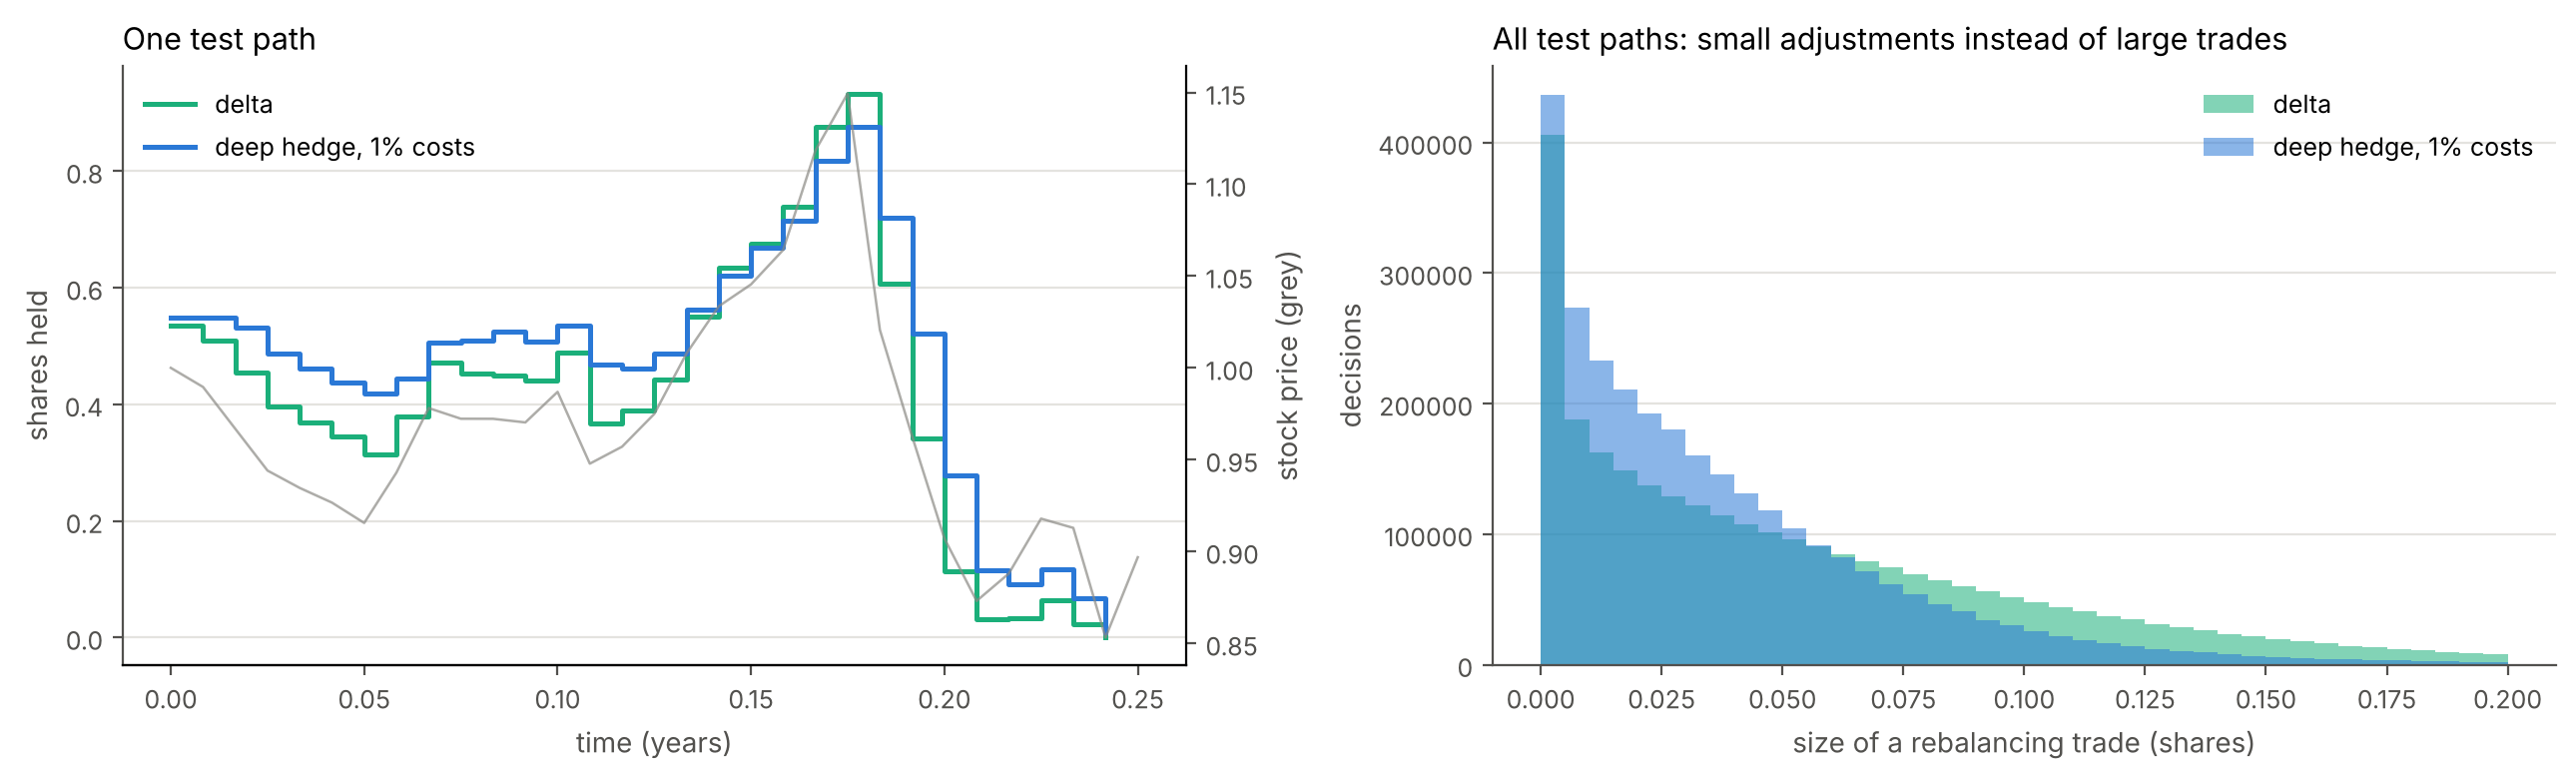

In [4]:
H_deep = {eps: holdings(models[eps], S_test) for eps in [0.0, 0.01]}
rebalancing = lambda H: (H[:, 1:] - H[:, :-1]).abs()        # trades at t_1, ..., t_29

print(f"{'':24s}{'mean |trade|':>14s}{'trades < 0.01 share':>21s}{'mean |H - delta|':>18s}")
for name, H in [("delta hedge", H_delta), ("deep hedge, no costs", H_deep[0.0]), ("deep hedge, 1% costs", H_deep[0.01])]:
    d = rebalancing(H)
    print(f"{name:24s}{d.mean():14.4f}{(d < 0.01).double().mean():21.1%}{(H - H_delta).abs().mean():18.4f}")

t = torch.arange(N) * T / N
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.step(t, H_delta[0], where="post", color=COLORS["delta"], lw=1.8, label="delta")
ax.step(t, H_deep[0.01][0], where="post", color=COLORS["deep"], lw=1.8, label="deep hedge, 1% costs")
ax.set_xlabel("time (years)")
ax.set_ylabel("shares held")
ax.set_title("One test path", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
style(ax)
ax2 = ax.twinx()
ax2.plot(torch.arange(N + 1) * T / N, S_test[0], color=COLORS["grey"], lw=0.9, alpha=0.7)
ax2.set_ylabel("stock price (grey)", color=MUTED)
ax2.tick_params(colors=MUTED, labelsize=9)
for side in ("top", "left"):
    ax2.spines[side].set_visible(False)

ax = axes[1]
bins = np.linspace(0, 0.2, 41)
ax.hist(rebalancing(H_delta).flatten().numpy(), bins=bins, color=COLORS["delta"], alpha=0.55, label="delta")
ax.hist(rebalancing(H_deep[0.01]).flatten().numpy(), bins=bins, color=COLORS["deep"], alpha=0.55, label="deep hedge, 1% costs")
ax.set_xlabel("size of a rebalancing trade (shares)")
ax.set_ylabel("decisions")
ax.set_title("All test paths: small adjustments instead of large trades", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
style(ax)
plt.tight_layout()
save(fig, "part3_trades")
plt.show()

The network does not stop trading. It replaces the large trades of the delta hedge with small adjustments: its average trade is a third smaller (0.039 against 0.059 shares), and its holding stays on average 0.05 share away from delta. On the path shown, it does not follow the price all the way down at the start and only sells gradually after the peak.

## A stronger benchmark: the no-trade band

The classical answer to costs is a band around delta (Whalley & Wilmott, 1997): keep the current holding as long as it is within $B$ of delta, otherwise trade only to the nearest edge. Their asymptotic analysis gives

$$
B = \left(\frac{3\,\varepsilon\, S\, \Gamma^2}{2\lambda}\right)^{1/3}
$$

for a seller with risk aversion $\lambda$. We absorb the unknown constant into a factor $c$, $B = c\,(\varepsilon S \Gamma^2)^{1/3}$, and choose $c$ on the training paths for each cost level. This is the benchmark to beat: it already trades less than delta, and its width is tuned on the same data as the network.

   cost  band c     delta      band      deep  deep vs delta  deep vs band


   0.0%    0.00   0.08998   0.08998   0.08883          -1.3%         -1.3%


   0.2%    0.10   0.09688   0.09622   0.09436          -2.6%         -1.9%


   0.5%    0.10   0.10766   0.10507   0.10213          -5.1%         -2.8%


   1.0%    0.15   0.12632   0.11904   0.11415          -9.6%         -4.1%


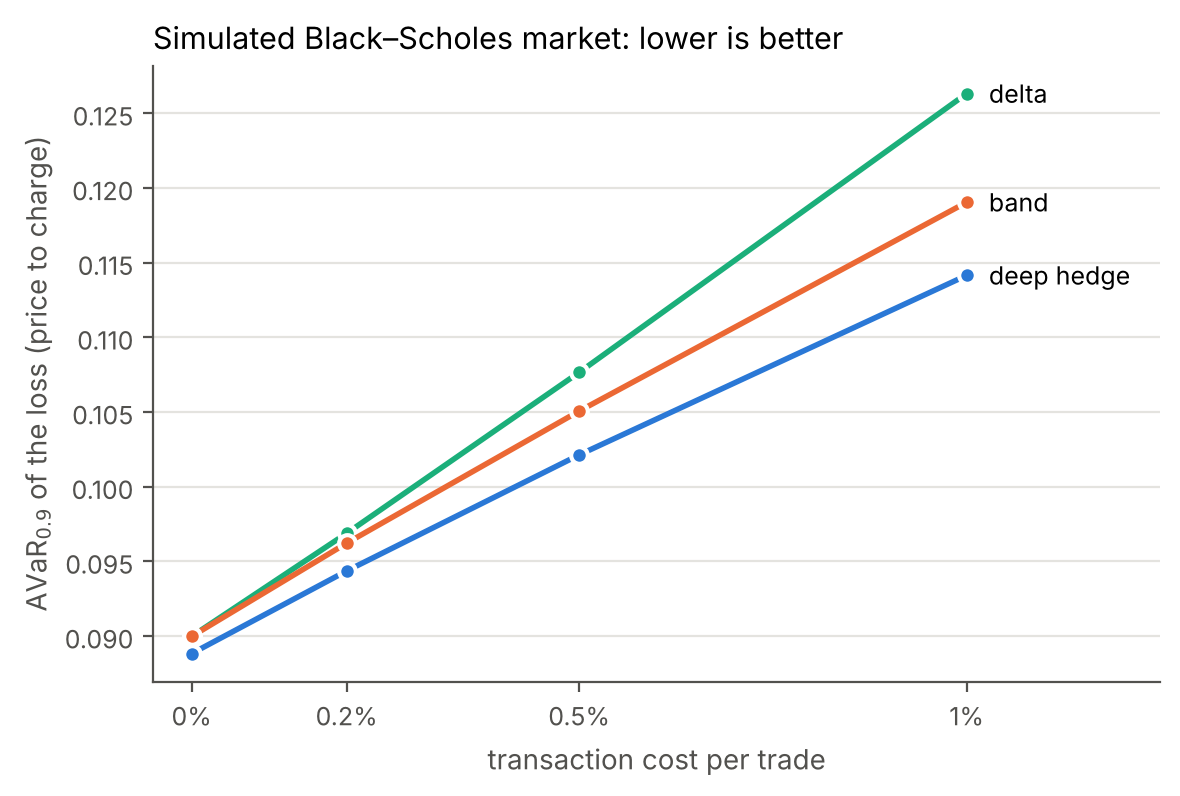

In [5]:
S_train64 = S_train.double()
best_c = {eps: tune_band(S_train64, eps, sigma) for eps in eps_levels}

rows = {}
print(f"{'cost':>7s}{'band c':>8s}{'delta':>10s}{'band':>10s}{'deep':>10s}{'deep vs delta':>15s}{'deep vs band':>14s}")
for eps in eps_levels:
    a_delta = avar(hedging_loss(H_delta, S_test, eps=eps)[0], 0.9)
    a_band = avar(hedging_loss(band_holdings(S_test, eps, best_c[eps], sigma), S_test, eps=eps)[0], 0.9)
    a_deep = avar(hedging_loss(holdings(models[eps], S_test), S_test, eps=eps)[0], 0.9)
    rows[eps] = (a_delta, a_band, a_deep)
    print(f"{eps:7.1%}{best_c[eps]:8.2f}{a_delta:10.5f}{a_band:10.5f}{a_deep:10.5f}"
          f"{a_deep / a_delta - 1:15.1%}{a_deep / a_band - 1:14.1%}")

fig, ax = plt.subplots(figsize=(6.5, 4))
x = [100 * e for e in eps_levels]
for i, (name, color) in enumerate([("delta", COLORS["delta"]), ("band", COLORS["band"]), ("deep hedge", COLORS["deep"])]):
    y = [rows[e][i] for e in eps_levels]
    ax.plot(x, y, color=color, lw=2, marker="o", ms=6, mec="white", mew=1.5)
    ax.annotate(name, (x[-1], y[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(-0.05, 1.25)
ax.set_xticks(x, [f"{v:g}%" for v in x])
ax.set_xlabel("transaction cost per trade")
ax.set_ylabel("AVaR$_{0.9}$ of the loss (price to charge)")
ax.set_title("Simulated Black–Scholes market: lower is better", loc="left", fontsize=11)
style(ax)
save(fig, "part3_costs")
plt.show()

The band recovers part of the gain, but the network beats it at every cost level, by 1.9% to 4.1%. The band is an asymptotic rule for small costs with a fixed shape around delta; the network can choose any trade at any date, and learns the trade-off between hedging error and costs directly from the loss.

## Is the gain over the band robust?

The same models on 50 independent test sets of 10,000 paths, compared set by set, then two more training seeds.

In [6]:
gain = {eps: [] for eps in eps_levels[1:]}
for i in range(50):
    S_new = simulate.gbm_paths(10_000, seed=1000 + i)
    for eps in gain:
        a_band = avar(hedging_loss(band_holdings(S_new, eps, best_c[eps], sigma), S_new, eps=eps)[0], 0.9)
        a_deep = avar(hedging_loss(holdings(models[eps], S_new), S_new, eps=eps)[0], 0.9)
        gain[eps].append(a_deep / a_band - 1)

print(f"{'cost':>7s}{'mean gain':>11s}{'std':>8s}{'worst set':>11s}{'deep better in':>16s}")
for eps, g in gain.items():
    g = np.array(g)
    print(f"{eps:7.1%}{g.mean():11.1%}{g.std():8.1%}{g.max():11.1%}{f'{np.sum(g < 0)} of 50':>16s}")

print(f"\n{'cost':>7s}{'seed 0':>9s}{'seed 1':>9s}{'seed 2':>9s}   (deep vs band, 100,000 test paths)")
for eps in [0.005, 0.01]:
    a_band = rows[eps][1]
    gains = [rows[eps][2] / a_band - 1]
    for seed in [1, 2]:
        gains.append(avar(hedging_loss(holdings(train(eps, seed), S_test), S_test, eps=eps)[0], 0.9) / a_band - 1)
    print(f"{eps:7.1%}" + "".join(f"{g:9.2%}" for g in gains))

   cost  mean gain     std  worst set  deep better in
   0.2%      -2.0%    0.2%      -1.5%        50 of 50
   0.5%      -2.8%    0.2%      -2.4%        50 of 50
   1.0%      -4.1%    0.3%      -3.5%        50 of 50

   cost   seed 0   seed 1   seed 2   (deep vs band, 100,000 test paths)


   0.5%   -2.79%   -2.81%   -2.84%


   1.0%   -4.11%   -4.07%   -4.13%


The network beats the band on all 50 test sets at every cost level, the gain varies by only 0.2 to 0.3 points from one set to the next, and three training seeds give the same gain. In a simulated Black–Scholes market the result is solid. The real question is whether it survives real prices, where the model used to train the network is wrong. That is part 4.